---
## **0. 준비**
---

In [1]:
%%html
<style>
    body {
        /* change --vscode-font-family if it's different on your system */
        --vscode-font-family: "SeoulNamsanC";
    }
</style>

In [2]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import GoogleGenerativeAI

from langgraph.graph import StateGraph, START, END                          
from typing import TypedDict                                                
from langchain_classic.output_parsers import EnumOutputParser
from typing import Annotated, Optional, Union
from langchain_core.runnables.config import RunnableConfig

In [3]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from IPython.display import display, Markdown

In [4]:
import config
config.set_environment()

---
## **도구의 기본 개념**
---

- 에이전트 능력의 실제 구현 방식을 이해하기 위해서는 **먼저 LLM의 도구 호출 기능과 LangChain에서의 구현 방법을 살펴봐야함 (도구의 기본 개념)**
- **특히 ReACT(Reasoning + Acting) 패턴을 분석** 해 LLM이 도구를 통해 외부 환경과 상호작용하며 작업 성능을 높이는 방식을 알아야함
- 추가로 다루는 내용:
    - LangChain에서 **도구를 정의하는 방법과 사전 구축된 도구**들의 종류
    - **사용자 정의 도구 개발** 방법, 오류 처리 전략, **고급 도구 호출 기능** 등이 포함
    - 에이전트 개념을 소개하고 LangGraph로 고급 에이전트를 구축하는 패턴 학습
- 계획 및 해결(plan-and-solve) 설계 패턴을 적용해 웹 검색, arXiv, 위키피디아 도구를 활용하는 연구용 에이전트를 LangGraph로 개발해 볼 것

---
### **도구의 기본 개념**
- LLM은 우수한 추론 능력을 바탕으로, 외부 환경과 도구를 통해 상호작용 할 수 있음.
- **도구란, API나 인터페이스 형태로, 모델이 외부 세계와 연결될 수 있게 해주는 수단**
- 도구를 사용할 때 LLM은 다음 세 가지를 생성:
    - TBD

<hr style="border:0;border-top:1.5px dashed gray;">

#### **출력 파싱**
- 출력 파싱은 자연어 응답이 아닌 구조화된 데이터가 필요한 대규모 워크플로에서 LLM을 통합할때 필수
- 이는 프롬프트에 명확한 지침을 포함하고 결과를 파싱하는 방식으로 구현
- 아래 예시:
    - 목적 : 주니어 자바 프로그래머에 대한 특정 직무 설명이 적합한지 파이프라인에서 평가하고, LLM의 판단을 기반으로 채용공고 게시 여부를 결정

In [92]:
# 예시: 채용 공고 게시 여부를 결정 

from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate

llm = ChatOpenAI(model = "gpt-6-luna", use_responses_api=True)

job_description : str = """백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다..."""

prompt_template = (
    "전달하는 JD를 보고 주니어 자바에 적당한지 결정해봐."
    "\nJob Description:\n{job_description}\n"
)

result = llm.invoke(prompt_template.format(job_description=job_description))

# 출력
print("\n[답변]")
display(Markdown(result.text) or "답변 텍스트 없음: 토큰 상한과 응답 상태를 확인하세요.")

print("\n[추론 요약 — 내부 사고 원문이 아닙니다]")                     

summaries = [
    block["reasoning"]                                                 
    for block in result.content_blocks                               
    if block.get("type") == "reasoning" and block.get("reasoning")]    
print("\n".join(summaries) if summaries else                            
        "이 응답에는 공개된 추론 요약이 없습니다.")                       


[답변]


이 JD는 **주니어 자바 개발자에게 적합하지 않습니다.**

- **백엔드 경력 7년 이상**을 명시해 시니어급을 찾고 있습니다.
- 분산 시스템, 마이크로서비스, 성능 튜닝, 대규모 시스템 설계에 대한 **심도 있는 실무 경험**을 요구합니다.

따라서 주니어라면 요구 경력과 기술 깊이 모두에서 차이가 큽니다. 경력 요건이 유연하다는 안내가 따로 없다면, **주니어/신입 또는 경력 1~3년 대상 공고**를 찾는 편이 좋습니다.


[추론 요약 — 내부 사고 원문이 아닙니다]
이 응답에는 공개된 추론 요약이 없습니다.


> - LLM의 출력은 자유로운 형식의 텍스트로 생성되기 때문에 파이프라인 후속 단계에서 파싱이나 해석이 어려울 수 있음
> - 프롬프트에 구체적인 지시 사항을 넣어 출력을 제어하고 후속 단계를 고려할 수 있음

In [93]:
prompt_template_enum = (
    "전달하는 JD를 보고 주니어 자바에 적당한지 결정해봐."
    "\nJob Description:\n{job_description}\n"
    "\nAnswer only YES or NO."
)

result_enum = llm.invoke(prompt_template_enum.format(job_description=job_description))
display(Markdown(result_enum.text))

NO

- **OutputParser**
    - LangChain은 다양한 OutputParser를 제공
    - 이들은 **LLM이 생성한 출력을 가져와 원하는 형식(필요한 경우 스키마를 검사하면서)으로 파싱 시도**
    - **List, CSV, 열거형(enum), DataFrame, Pydantic 모델, JSON, XML** 등이 그 대상
    - 각 파서는 `BaseGenerationOuputParser` 인터페이스를 구현
        - Runnable 인터페이스를 확장하며 추가적으로 `parse_result` 메서드를 포함
        - 해당 메서드를 통해 LLM의 출력을 정형 데이터로 안전하게 변환

In [94]:
# 출력을 열거형(Enum)으로 파싱하는 예제

from enum import Enum                                                       #정해진 이름과 값을 갖는 선택지 묶음인 Enum
from langchain_classic.output_parsers import EnumOutputParser               #텍스트를 지정한 Enum의 멤버로 변환하는 LangChain 출력 파서 클래스
from langchain_core.messages import HumanMessage

    # 적합 여부를 두 선택지로 나타내는 사용자 정의 Enum 타입을 만듭니다.
class IsSuitableJobEnum(Enum):
    YES = "YES"                                                             #멤버 이름은 YES, 실제 문자열 값도 "YES", 서로 다른 개념이지만 여기서는 같게 지정
    NO = "NO"                                                               #IsSuitableJobEnum.NO로 이 멤버에 접근. 멤버 자체는 문자열 "NO"와 다름

    # (중요) 어떤 Enum으로 변환할지 위에서 만든 클래스 자체를 전달, IsSuitableJobEnum()을 호출하는 것이 아님
parser = EnumOutputParser(enum=IsSuitableJobEnum)                           #내부적으로 문자열 양끝 공백과 줄바꿈을 제거한 뒤, 해당 값의 Enum 멤버를 찾아 반환

    # 아래는 정상 동작을 확인하는 작은 예제들
    # assert는 비교가 True면 조용히 통과하고 False면 AssertionError를 발생시키는 검산 문법.
assert parser.invoke("NO") == IsSuitableJobEnum.NO                          #"NO"를 파싱한 결과가 NO 멤버인지 검사, 결과는 문자열이나 bool이 아니라 Enum 멤버임.
assert parser.invoke("YES\n") == IsSuitableJobEnum.YES                      #해당 Parser는 문자열 끝의 \n(줄바꿈)은 제거하므로 "YES"와 같은 결과가 나오는지 검사.
assert parser.invoke(" YES \n") == IsSuitableJobEnum.YES                    #양끝의 공백과 줄바꿈을 제거한 뒤 YES 멤버로 변환하는지 검사합니다.
assert parser.invoke(HumanMessage(content="YES")) == IsSuitableJobEnum.YES  #HumanMessage의 텍스트 내용을 꺼내 같은 규칙으로 파싱하는지 검사, 실제 LLM 응답은 보통 AIMessage이지만, 여기서는 메시지 입력도 처리한다는 것을 보여줌


---
#### **14번 셀 학습 노트: 파서는 무엇을 하는가?**
- **파싱(parsing)** 은 받은 데이터를 규칙에 맞게 읽어 프로그램에서 사용할 형태로 변환하는 작업이다. 
- 여기서 `EnumOutputParser`는 적합 여부를 새로 판단하지 않는다. **이미 받은 답변이 허용된 선택지인지 검사하고, 문자열을 Enum 멤버로 변환**한다.

```text
LLM의 답변 문자열 또는 메시지
    ↓ 텍스트 추출 및 양끝 공백 제거
"YES" 또는 "NO"인지 확인
    ↓ 일치하는 Enum 멤버로 변환
IsSuitableJobEnum.YES 또는 IsSuitableJobEnum.NO
```
<hr style="border:0;border-top:1.5px dashed gray;">

**1. Enum은 선택지를 명확하게 정의한다**

```python
class IsSuitableJobEnum(Enum):
    YES = "YES"
    NO = "NO"
```

| 표현 | 의미 |
|---|---|
| `IsSuitableJobEnum` | 사용자 정의 Enum 타입 |
| `IsSuitableJobEnum.YES` | YES 선택지를 나타내는 Enum 멤버 |
| `IsSuitableJobEnum.YES.name` | 멤버 이름인 문자열 `"YES"` |
| `IsSuitableJobEnum.YES.value` | 멤버에 저장된 값인 문자열 `"YES"` |

멤버 이름과 값은 다르게 정할 수도 있다. 이 파서는 **멤버의 문자열 값(`.value`)** 과 모델 답변을 맞춘다. `IsSuitableJobEnum.YES` 자체는 `"YES"`나 `True`가 아니다.

<hr style="border:0;border-top:1.5px dashed gray;">

**2. 파서 생성과 호출은 별개다**

```python
parser = EnumOutputParser(enum=IsSuitableJobEnum)
decision = parser.invoke(" YES \n")
```

**첫 줄은 변환 규칙을 가진 객체를 만들고**, 둘째 줄은 실제 입력에 그 규칙을 적용한다. 이 `invoke()`는 **파서를 실행하는 호출**이다. 모델의 `invoke()`와 이름은 같지만 모델에게 질문하는 작업은 아니다.

현재 구현의 핵심은 다음과 같다.

```python
# 이해를 위한 핵심 동작 요약
cleaned_text = " YES \n".strip()
decision = IsSuitableJobEnum(cleaned_text)
```

`strip()`은 문자열 양끝의 공백·줄바꿈 등을 제거한다. `IsSuitableJobEnum("YES")`는 해당 값을 가진 YES 멤버를 찾는다. 일치하는 값이 없으면 파서는 `OutputParserException`을 발생시킨다.

<hr style="border:0;border-top:1.5px dashed gray;">

**3. 네 개의 assert는 정상 동작을 확인하는 작은 예제다**

| 입력 | 결과 | 이유 |
|---|---|---|
| `"NO"` | `IsSuitableJobEnum.NO` | 허용된 값과 일치 |
| `"YES\n"` | `IsSuitableJobEnum.YES` | 끝 줄바꿈 제거 |
| `" YES \n"` | `IsSuitableJobEnum.YES` | 양끝 공백·줄바꿈 제거 |
| `HumanMessage(content="YES")` | `IsSuitableJobEnum.YES` | 메시지의 텍스트 내용을 파싱 |

모든 `assert`가 통과해도 별도 출력은 없다. 출력해서 보고 싶다면 새 셀에서 다음만 실행해도 된다. API 호출은 발생하지 않는다.

```python
decision = parser.invoke(" YES \n")
print(decision)        # IsSuitableJobEnum.YES
print(decision.name)   # YES
print(decision.value)  # YES
print(type(decision))  # <enum 'IsSuitableJobEnum'>
```
<hr style="border:0;border-top:1.5px dashed gray;">

**4. 자동으로 무엇이든 고쳐 주지는 않는다**

`"yes"`, `"Yes"`, `"YES."`, `"YES, 적합합니다"`는 양끝 공백을 제거해도 `"YES"`와 다르므로 현재 파서에서는 실패한다. 앞 셀의 지시가 `Answer only Yes or No.`라면, 모델이 대소문자를 그대로 따라 `Yes`라고 답할 수 있다. 이 Enum에 맞추려면 지시도 `Answer only YES or NO.`처럼 일치시키는 것이 좋다. 그래도 모델이 형식을 어길 수 있으므로 파싱 오류에 대한 처리는 별도로 필요하다.

메시지를 입력으로 지원한다고 해서 이미지·음성 등 모든 생성 결과를 이 파서가 이해하는 것은 아니다. 이 실습은 **텍스트 답변을 정해진 선택지로 변환**하는 경우다.

<hr style="border:0;border-top:1.5px dashed gray;">

**5. 그래프에서는 조건 분기에 활용할 수 있다**

```python
# 앞에서 모델 응답을 result_enum에 저장했다면 별도 모델 호출 없이 파싱 가능
# decision = parser.invoke(result_enum)
# is_suitable = decision == IsSuitableJobEnum.YES
# return {"is_suitable": is_suitable}  # 노드 함수 안에서 상태 업데이트로 반환
```

`bool(decision)`으로 YES/NO를 판단하면 안 된다. **이 일반 Enum에서는 YES와 NO 멤버 모두 참으로 평가되므로 반드시 YES 멤버와 비교**한다.

체인으로 구성하면 `프롬프트 템플릿 → LLM → EnumOutputParser → Enum 멤버`가 된다. 파서는 답변 형식을 검사할 뿐, 모델의 적합성 판단이 사실인지까지 검증하지 않는다.

In [ ]:
# 이제 앞서 살펴본 모든 요소를 하나의 체인으로 통합

chain = llm | parser
result = chain.invoke(prompt_template_enum.format(job_description=job_description))
print(result.value)

NO


In [ ]:
# 이제 이 체인을 LangGraph 워크플로의 일부로 만들어보자.

class JobApplicationState(TypedDict):
    job_description: str
    is_suitable: IsSuitableJobEnum
    application: str

analyze_chain = llm | parser

def analyze_job_description(state):
    prompt = prompt_template_enum.format(job_description=state["job_description"])
    result = analyze_chain.invoke(prompt)
    return {"is_suitable": result}

def is_suitable_condition(state: JobApplicationState):
    return state["is_suitable"] == IsSuitableJobEnum.YES

def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application", "actions": ["action2"]}

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)
builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges(
    "analyze_job_description", is_suitable_condition,
    {True: "generate_application", False: END})
builder.add_edge("generate_application", END)
graph = builder.compile()


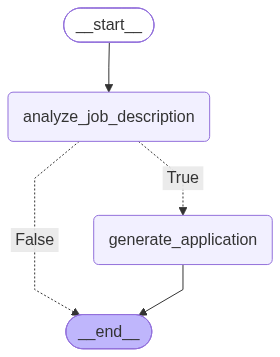

In [98]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

> - 새로 구축한 체인은 이제 analyze_job_description 노드를 표현하는 파이썬 함수의 일부
> - 조건부 에지 함수(condiational edge function)는 더 이상 문자열을 반환하지 않지만, **add_conditional_edges 함수에 반환값과 목적지 에지의 매핑을 추가함** -> 이는 워크플로 분기(branching)를 구현하는 한 가지 예시임

<hr style="border:0;border-top:1.5px dashed gray;">

#### **오류 처리(일단 skip)**

---
## **프롬프트 엔지니어링(일단 skip)**
---

---
## **제한된 컨택스트 창으로 작업하기(일단 skip)**
---

---
## **메모리 메커니즘의 이해(일단 skip)**
---